# Exercise 10 – Temperature dependence of a two-well system

**Week 2 · Monte Carlo sampling**

The potential has a deep, narrow well at $x = 0.5$ and a shallow, broad well
at $x = 4$. At low temperature the particle sits in the deep well; as the
temperature rises the *entropy* of the broad well makes it more and more
populated.

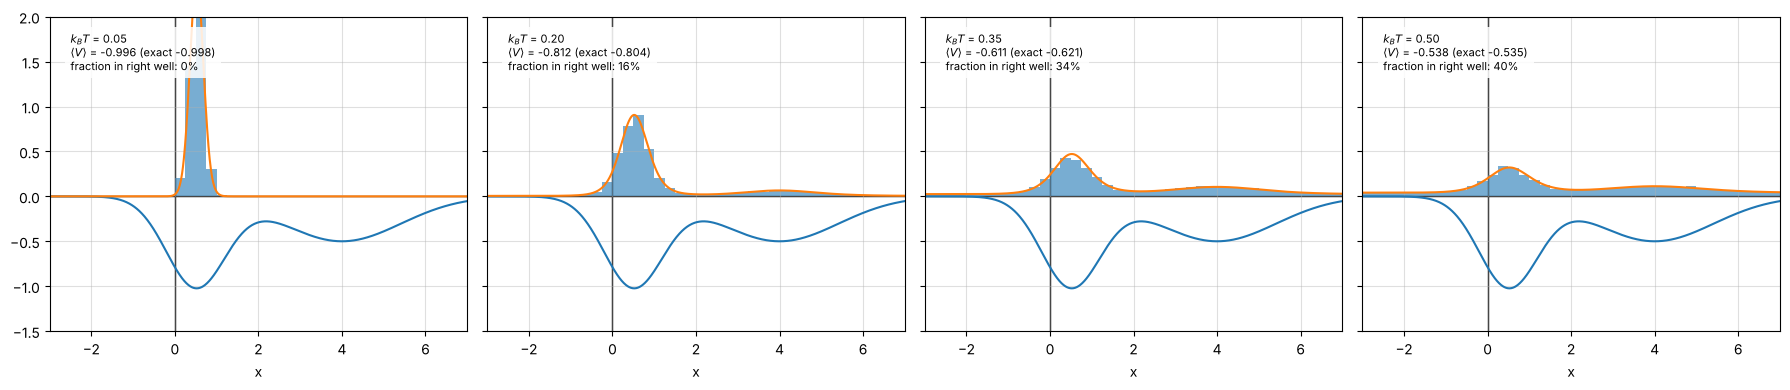

In [1]:
import matplotlib.pyplot as plt
import numpy as np

from comphy.montecarlo import boltzmann_pdf, metropolis, thermal_average
from comphy.plotting import annotate, setup_axes

rng = np.random.default_rng(0)
lims = (-3, 7)


def two_wells(x):
    x = np.asarray(x, dtype=float)
    return -0.5 * np.exp(-((x - 4) ** 2) / 4) - np.exp(-((x - 0.5) ** 2))


xs = np.linspace(*lims, 1000)
temperatures = np.linspace(0.05, 0.5, 4)

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, kT in zip(axes, temperatures):
    sample, _ = metropolis(two_wells, kT, x0=0.0, n_steps=20_000, lims=lims, rng=rng)
    ax.hist(sample, bins=40, range=lims, density=True, color="C0", alpha=0.6)
    ax.plot(xs, two_wells(xs), color="C0")
    ax.plot(xs, boltzmann_pdf(two_wells, kT, lims)(xs), color="C1")
    p_right = np.mean(sample > 2.2)
    annotate(ax, f"$k_BT$ = {kT:.2f}\n$\\langle V\\rangle$ = {two_wells(sample).mean():.3f} "
                 f"(exact {thermal_average(two_wells, kT, lims):.3f})\n"
                 f"fraction in right well: {p_right:.0%}", fontsize=8)
    setup_axes(ax, xlim=lims, ylim=(-1.5, 2), ylabel=None)
fig.tight_layout()
plt.show()

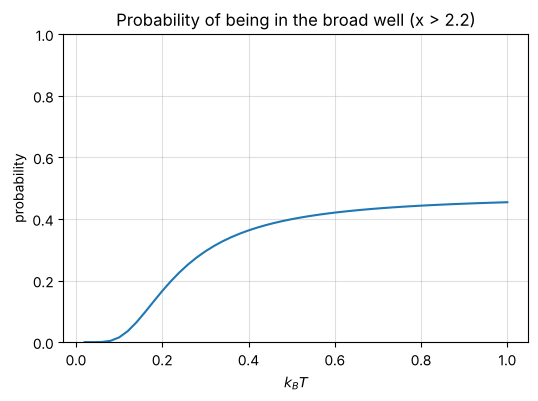

In [2]:
kTs = np.linspace(0.02, 1.0, 50)
pdfs = [boltzmann_pdf(two_wells, kT, lims) for kT in kTs]
grid = np.linspace(*lims, 4000)
p_right = [np.trapezoid(p(grid[grid > 2.2]), grid[grid > 2.2]) for p in pdfs]

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(kTs, p_right)
ax.set(xlabel="$k_BT$", ylabel="probability", ylim=(0, 1),
       title="Probability of being in the broad well (x > 2.2)")
ax.grid(True, alpha=0.4)
plt.show()